In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# Books, full 48 — what do the models want, and what does a contract do? (2026-10-13)

4 instruct models × 5 prompts (no contract + 4 genre contracts), 48 famous books, all pairs in both orders.
Design: [books_domain_design.ipynb](books_domain_design.ipynb); pilot: [books_pilot.ipynb](books_pilot.ipynb).

Sections: 0 the data · 1 sanity · 2 the default ranking · 3 what explains it · 4 contracts ·
5 inside the contract · 6 findings.

## 0. The data

### The items: 48 famous books
From **goodbooks-10k** — the 10,000 most-rated books on Goodreads, with how many readers put each book on each
"shelf" (a reader-made label such as `fantasy`, `sci-fi`, `classic`). Built by
[src/books/make_books.py](../src/books/make_books.py) → `src/books/books.csv`.

How the 48 were picked: **fame first, then balance.**
1. the 32 most-rated books;
2. add books until every genre has at least 8;
3. fill up to 48, at most 18 per genre.

Always the first book of a series only, at most 2 books per author, English only.
Result: years 1595–2015, Goodreads rating 3.51–4.45, 0.5M–4.8M ratings each.

### The features
| feature | values | does the model see it? |
|---|---|---|
| title, author, year | text | **yes** — the only thing in the prompt |
| 8 genre tags: `fantasy`, `science-fiction`, `romance`, `mystery-thriller`, `young-adult`, `classics`, `historical-fiction`, `nonfiction` | `yes` / `no` | **no** — hidden; used by the analysis and by the contracts |
| Goodreads `average_rating`, `ratings_count` | numbers | no — used only in section 3 |

**How a tag is set.** Goodreads shelves are messy, so synonyms are merged into the 8 genres (`sci-fi`, `scifi`,
`dystopian` → `science-fiction`; `memoir`, `biography`, `history` → `nonfiction`; ...). A book gets a tag if
**at least 12%** of its genre shelvings go to that genre. A book can have several tags (here 1–3).
Section 5 also uses the raw share itself, called **typicality** (how much of the book's genre shelving is that
genre).

In [2]:
import json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from src.bt import FeatureBT
import src.alternatives as alt
from src.books import make_books as mb
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 30)

TAGS = alt.book_tags
BOOK = {b["title"]: b for b in alt.books}
meta = pd.read_csv("src/books/books.csv").set_index("title")
MODELS = ["qwen-32B", "qwen-72B", "gemma-27B", "olmo-32B"]
CONS = ["none", "fantasy=yes", "mystery-thriller=yes", "romance=yes", "classics=yes"]
FIG = "figs/books"; os.makedirs(FIG, exist_ok=True)
SHORTC = {"none": "none", "fantasy=yes": "fantasy", "mystery-thriller=yes": "mystery", "romance=yes": "romance", "classics=yes": "classics"}

# Palette (dataviz reference, validated): blue = the contract / the requested tag, gray = baseline / other.
BLUE, GRAY, INK, INK2 = "#2a78d6", "#a3a29d", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK2,
                     "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
                     "axes.titlesize": 11, "figure.facecolor": "white"})
# One fixed colour + marker per model (dataviz categorical slots 1-4, validated; the marker is the second cue).
MC = dict(zip(MODELS, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"])); MK = dict(zip(MODELS, "osD^"))
GRID = "#e5e4df"

def model_dots(ax, df, xlab, zero=True):
    """rows of df = y categories (top to bottom), columns = MODELS; one marker per model, slightly offset."""
    y = np.arange(len(df))[::-1]
    if zero: ax.axvline(0, color=GRAY, lw=1, zorder=0)
    for i, m in enumerate(MODELS):
        ax.scatter(df[m], y + (1.5 - i) * 0.13, s=46, color=MC[m], marker=MK[m], edgecolor="white", linewidth=1.2, label=m, zorder=3)
    ax.set_yticks(y, df.index); ax.tick_params(axis="y", length=0)
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True); ax.set_xlabel(xlab)

runs = {}
for f in sorted(glob.glob("data/books/*/config.json")):
    d = os.path.dirname(f)
    if not os.path.isfile(d + "/scores.csv"):        # incomplete or still running: skip
        print("skip (no scores.csv):", d); continue
    c = json.load(open(f))
    assert c["frame"]["name"] == "reading"
    k = (f"{c['model_family']}-{c['model_size']}B", c["constraints_id"])
    assert k not in runs, f"duplicate run {k}"
    runs[k] = pd.read_csv(d + "/scores.csv")
    assert len(runs[k]) == 48 * 47 * 5, (k, len(runs[k]))
print(len(runs), "runs; missing:", [(m, c) for m in MODELS for c in CONS if (m, c) not in runs])

20 runs; missing: []


### What the model is asked
Each query is one chat turn. The **system message** (same for every run):

> You are a helpful assistant. Answer shortly with only your choice with no explanation.

The **user message** = frame sentence + contract sentence (if any) + one of 5 templates. The printout below is
built from the saved `config.json` of a real run, for one real pair. The 5 templates differ only in the last
question line.

We do not let the model write an answer. We read the log-probability it gives to the answer `1` and to the
answer `2`. Every pair is asked in **both orders**, with all 5 templates: 48 × 47 × 5 = **11,280 queries per
run**.

In [3]:
c0 = json.load(open("data/books/1447451/config.json"))    # qwen-72B, no contract
c1 = json.load(open("data/books/1447452/config.json"))    # qwen-72B, fantasy
show = lambda b: f"{b['title']} by {b['author']} ({b['year']})"     # = format_book_to_text in data_collection.py
A, B = alt.books[0], alt.books[1]
for c in [c0, c1]:
    print(f"----- contract: {c['constraints_id']} -----")
    print(c["prompt_prefix"] + "\n" + c["templates"]["0"].format(A=show(A), B=show(B)))
print("----- the 5 question lines -----")
for i, t in c0["templates"].items():
    print(i, t.strip().split("\n")[-2])

----- contract: none -----
I am looking for a book to read.
You have two options:
Option 1: The Hunger Games by Suzanne Collins (2008)
Option 2: Harry Potter and the Sorcerer's Stone by J.K. Rowling (1997)
Which do you prefer?
Answer: 
----- contract: fantasy=yes -----
I am looking for a book to read. I prefer fantasy.
You have two options:
Option 1: The Hunger Games by Suzanne Collins (2008)
Option 2: Harry Potter and the Sorcerer's Stone by J.K. Rowling (1997)
Which do you prefer?
Answer: 
----- the 5 question lines -----
0 Which do you prefer?
1 Do you prefer option 1 or option 2?
2 What is your preference?
3 Which option do you prefer?
4 Between them, which do you favor?


### The contracts
A contract is one extra sentence after the frame, `"I prefer <genre>."`. It names the genre only — not a book, not
quality. In the data it is stored as `{tag: "yes"}`; a book **satisfies** it if it has that tag.

| contract (`constraints_id`) | sentence added to the prompt | books that satisfy it |
|---|---|---|
| `none` | — (only "I am looking for a book to read.") | — |
| `fantasy=yes` | I prefer fantasy. | 10 |
| `mystery-thriller=yes` | I prefer mysteries and thrillers. | 8 |
| `romance=yes` | I prefer romance. | 8 |
| `classics=yes` | I prefer classics. | 26 |

`classics` was meant as the **control**: it asks for what the models already like (section 3).

### The models
`Qwen/Qwen2.5-32B-Instruct`, `Qwen/Qwen2.5-72B-Instruct`, `google/gemma-3-27b-it`,
`allenai/OLMo-2-0325-32B-Instruct`. Frame `reading` in every run. 4 models × 5 prompts = 20 runs.

### The measure
For a pair (x, y), $m(x,y)$ = log-prob of "x" − log-prob of "y" when x is shown first.
**D = (m(x,y) − m(y,x)) / 2** removes the slot bias (the pull to answer "1" or "2"). A book's **score** = its
mean D against the other 47 books. Scores are zero-sum across books: only relative standing is measurable.

In [4]:
def Dtab(df):
    """position-corrected D per (template, ordered pair); both orders present"""
    m = df.assign(m=df.score_a - df.score_b)[["template_idx", "a_title", "b_title", "m"]]
    r = m.rename(columns={"a_title": "b_title", "b_title": "a_title"}).assign(m=-m.m)
    return pd.concat([m, r]).groupby(["template_idx", "a_title", "b_title"]).m.mean().reset_index()

D = {k: Dtab(df) for k, df in runs.items()}
score = {k: d.groupby("a_title").m.mean() for k, d in D.items()}       # Borda score per book
has = lambda b, t: BOOK[b][t] == "yes"

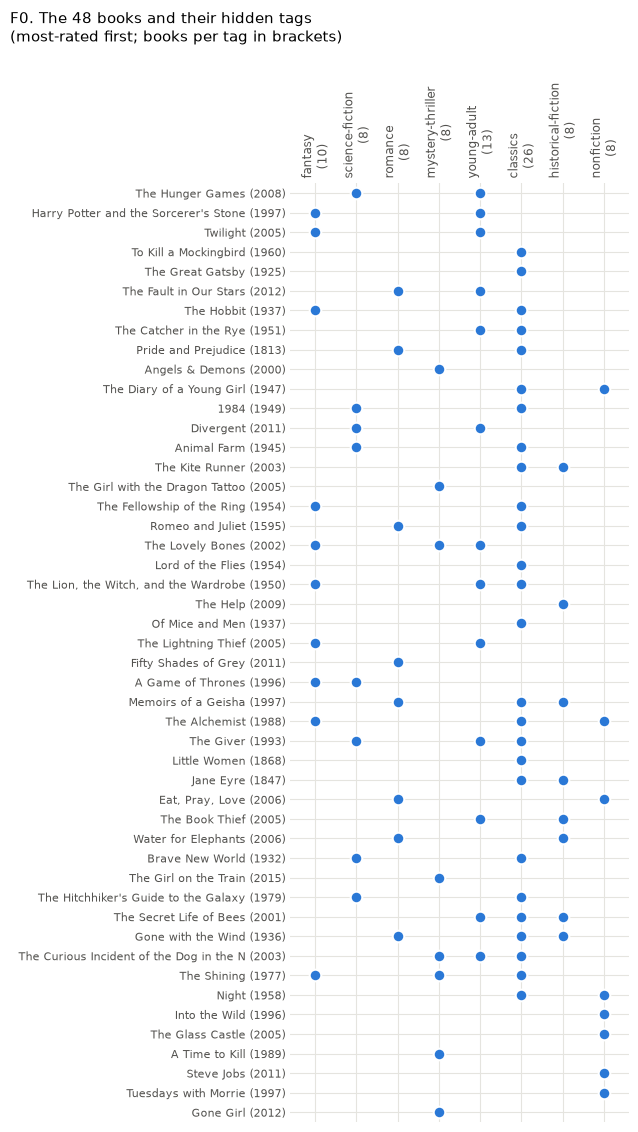

tags per book: {1: 16, 2: 23, 3: 9}


In [5]:
# F0: which book has which hidden tag. Rows sorted by fame (ratings count).
T = meta[TAGS].loc[[b["title"] for b in alt.books]]
fig, ax = plt.subplots(figsize=(6.4, 11.5))
yy, xx = np.nonzero(T.values)
ax.scatter(xx, yy, s=70, color=BLUE, edgecolor="white", linewidth=1.5)
ax.set_xticks(range(len(TAGS)), [f"{t}\n({T[t].sum()})" for t in TAGS], rotation=90, fontsize=8.5); ax.xaxis.tick_top()
ax.set_yticks(range(len(T)), [f"{b[:40]} ({BOOK[b]['year']})" for b in T.index], fontsize=8)
ax.set_xlim(-0.6, len(TAGS) - 0.4); ax.set_ylim(len(T) - 0.5, -0.5)
ax.grid(color=GRID, lw=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)
[s.set_visible(False) for s in ax.spines.values()]
fig.suptitle("F0. The 48 books and their hidden tags\n(most-rated first; books per tag in brackets)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.975)); fig.savefig(f"{FIG}/F0_tags.png", dpi=150); plt.show()
print("tags per book:", T.sum(axis=1).value_counts().sort_index().to_dict())

- **`classics` is by far the biggest tag: 26 of 48 books.** `young-adult` has 13, `fantasy` 10, every other tag 8.
- **Most books have 2 tags** (23 books); 16 have one, 9 have three. So the tags overlap: e.g. Harry Potter is
  `fantasy` + `young-adult`, The Hitchhiker's Guide is `science-fiction` + `classics`.
- **The tags come from readers, not from a library catalogue.** Twilight is `fantasy` + `young-adult`, not
  `romance` (only 7% of its genre shelves); The Alchemist is `fantasy` + `classics` + `nonfiction`. This matters in
  section 5.

## 1. Sanity

Four checks per run:
- **saturated** = share of queries where the model is sure (log-prob of the winner ≈ 0);
- **γ (slot bias)** = mean raw margin, slot 1 − slot 2 (the book content cancels: every pair is asked in both
  orders);
- **template agreement** = mean Spearman between the book rankings of the 5 templates;
- **spread** = SD of the 48 book scores (how loud the preference is).

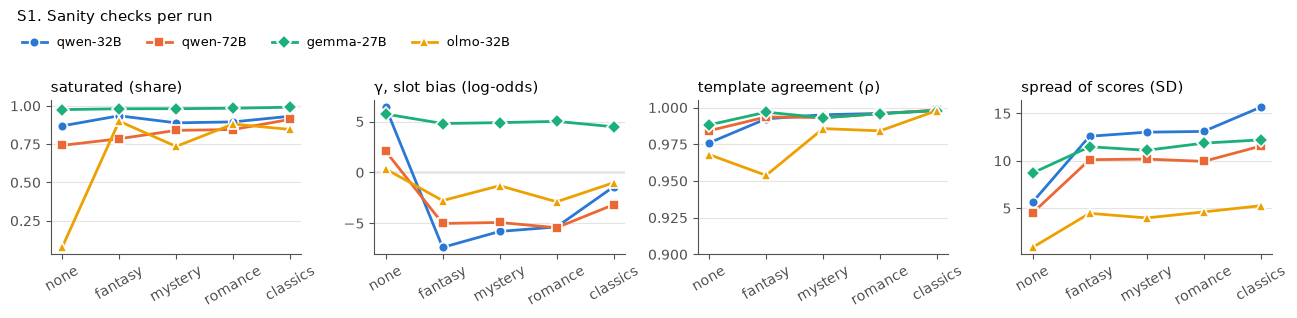

In [6]:
rows = []
for (m, c), df in runs.items():
    mm = df.score_a - df.score_b
    t = D[(m, c)].groupby(["a_title", "template_idx"]).m.mean().unstack().corr(method="spearman").values
    rows.append(dict(model=m, contract=c, sat=(df[["score_a", "score_b"]].max(axis=1) > -0.1).mean(),
                     gamma=mm.mean(), tmpl_agree=t[np.triu_indices_from(t, 1)].mean(), spread=score[(m, c)].std()))
SAN = pd.DataFrame(rows).set_index(["model", "contract"]).reindex([(m, c) for m in MODELS for c in CONS]).dropna(how="all")

# S1: the four checks, per model, across the 5 prompts.
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
x = np.arange(len(CONS))
for ax, (col, title) in zip(axes, [("sat", "saturated (share)"), ("gamma", "γ, slot bias (log-odds)"),
                                   ("tmpl_agree", "template agreement (ρ)"), ("spread", "spread of scores (SD)")]):
    for m in MODELS:
        ax.plot(x, SAN.loc[m, col].reindex(CONS), color=MC[m], marker=MK[m], lw=2, ms=7, mec="white", mew=1.2, label=m)
    if col == "gamma": ax.axhline(0, color=GRAY, lw=1, zorder=0)
    ax.set_xticks(x, [SHORTC[c] for c in CONS], rotation=30); ax.set_title(title, loc="left")
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
axes[2].set_ylim(0.9, 1.005)
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.935), frameon=False, ncol=4, fontsize=9)
fig.suptitle("S1. Sanity checks per run", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(f"{FIG}/S1_sanity.png", dpi=150); plt.show()

- **All 20 runs are clean**: the 5 templates agree at ρ 0.95–1.00.
- **olmo-32B without a contract is quiet**: only 8% saturated and spread 0.87, vs 74–98% and 4.5–8.7 for the others.
  It is still stable (ρ 0.97) and content-driven (section 2) — a real low-confidence default, not a bug. **Any
  contract makes it confident**: saturated 74–90%, spread 4.0–5.3.
- **A contract makes every model louder.** Spread with no contract → with a contract: qwen-32B 5.6 → 12.6–15.7,
  qwen-72B 4.5 → 9.9–11.5, gemma-27B 8.7 → 11.1–12.2, olmo-32B 0.9 → 4.0–5.3.
- **In qwen the slot bias flips sign under a contract**: γ +6.4 / +2.1 → −1.4 … −7.4. Gemma stays at +4.5 … +5.7.
  Same family pattern as on the laptops. `D` is immune to it.

## 2. The default ranking (no contract)

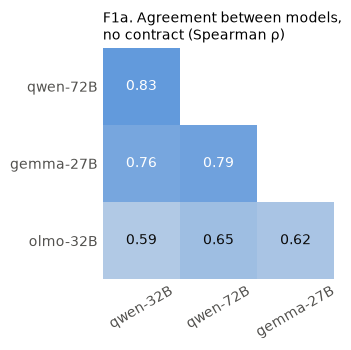

In [7]:
base = pd.DataFrame({m: score[(m, "none")] for m in MODELS})
rank = base.rank(ascending=False).astype(int)
order = rank.mean(axis=1).sort_values().index
CORR = base.corr(method="spearman")

# F1a: how much the four models agree on the default ranking.
fig, ax = plt.subplots(figsize=(4.4, 3.6))
cm = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blues", ["#f0efec", "#2a78d6"])
mask = np.triu(np.ones_like(CORR, bool))      # lower triangle only, no diagonal
ax.imshow(np.ma.array(CORR.values, mask=mask), cmap=cm, vmin=0.4, vmax=1)
for i in range(4):
    for j in range(i):
        v = CORR.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=10, color="white" if v > 0.75 else INK)
ax.set_xticks(range(3), MODELS[:3], rotation=30); ax.set_yticks(range(1, 4), MODELS[1:]); ax.set_xlim(-0.5, 2.5); ax.set_ylim(3.5, 0.5); ax.tick_params(length=0)
[s.set_visible(False) for s in ax.spines.values()]
ax.set_title("F1a. Agreement between models,\nno contract (Spearman ρ)", loc="left", fontsize=10)
fig.tight_layout(); fig.savefig(f"{FIG}/F1a_model_agreement.png", dpi=150); plt.show()

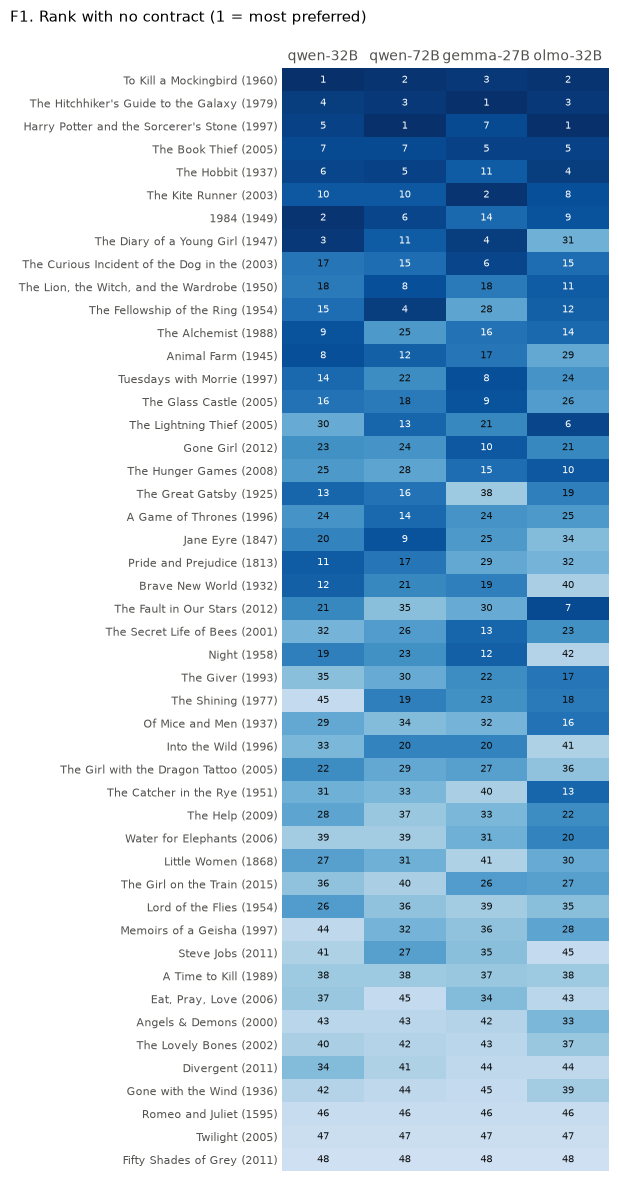

In [8]:
# F1: rank of every book per model (1 = most preferred), sorted by the mean rank.
fig, ax = plt.subplots(figsize=(6.2, 12))
R = rank.loc[order]
ax.imshow(R.values, cmap="Blues_r", vmin=1, vmax=60, aspect="auto")      # dark = preferred; capped so 48 stays readable
for i in range(R.shape[0]):
    for j in range(R.shape[1]):
        v = R.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=7.5, color="white" if v <= 16 else INK)
ax.set_xticks(range(len(MODELS)), MODELS); ax.xaxis.tick_top()
ax.set_yticks(range(len(order)), [f"{b[:38]} ({BOOK[b]['year']})" for b in order], fontsize=8)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
fig.suptitle("F1. Rank with no contract (1 = most preferred)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.985)); fig.savefig(f"{FIG}/F1_default_rank.png", dpi=150); plt.show()

In [9]:
print("bottom 3 per model:", {m: list(rank[m].sort_values().index[-3:]) for m in MODELS})
print("Romeo and Juliet:", rank.loc["Romeo and Juliet"].to_dict())

bottom 3 per model: {'qwen-32B': ['Romeo and Juliet', 'Twilight', 'Fifty Shades of Grey'], 'qwen-72B': ['Romeo and Juliet', 'Twilight', 'Fifty Shades of Grey'], 'gemma-27B': ['Romeo and Juliet', 'Twilight', 'Fifty Shades of Grey'], 'olmo-32B': ['Romeo and Juliet', 'Twilight', 'Fifty Shades of Grey']}
Romeo and Juliet: {'qwen-32B': 46, 'qwen-72B': 46, 'gemma-27B': 46, 'olmo-32B': 46}


- **The four models largely share one taste** (F1a): ρ 0.59–0.83. The two qwens agree most (0.83); OLMo agrees
  least with everyone (0.59–0.65).
- **Same bottom three in all four models** (F1, bottom rows): Romeo and Juliet 46th, Twilight 47th, Fifty Shades
  of Grey 48th.
- **Same top**: To Kill a Mockingbird, The Hitchhiker's Guide to the Galaxy and Harry Potter (mean rank 2.0, 2.8,
  3.5). Where the models disagree most is the middle (e.g. The Diary of a Young Girl: 3rd–11th in three models,
  31st in OLMo).

## 3. What explains the default?

(a) Goodreads: average rating (quality as readers judge it), ratings count (fame), year.
(b) The hidden tags: a fit-free view (mean score of tagged − untagged books) and the `FeatureBT` tag weights.

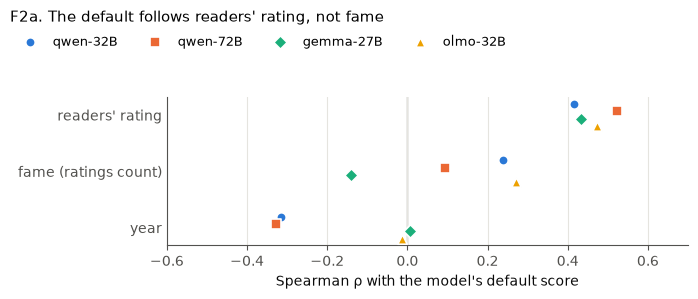

In [10]:
j = base.join(meta[["average_rating", "ratings_count", "year"]])
GR = pd.DataFrame({m: {c: spearmanr(j[m], j[c])[0] for c in ["average_rating", "ratings_count", "year"]} for m in MODELS})
GR.index = ["readers' rating", "fame (ratings count)", "year"]

# F2a: Spearman between the default score and three Goodreads facts.
fig, ax = plt.subplots(figsize=(7, 3.0))
model_dots(ax, GR, "Spearman ρ with the model's default score")
ax.set_xlim(-0.6, 0.7)
fig.legend(*ax.get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.935), frameon=False, ncol=4, fontsize=9)
fig.suptitle("F2a. The default follows readers' rating, not fame", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.84)); fig.savefig(f"{FIG}/F2a_goodreads.png", dpi=150); plt.show()

- **Quality, not fame.** Every model correlates with the readers' average rating (ρ 0.42–0.52) and not with the
  number of ratings (−0.14 … +0.27).
- **qwen leans old** (ρ −0.32 / −0.33 with year); gemma and OLMo do not (0.01, −0.01).

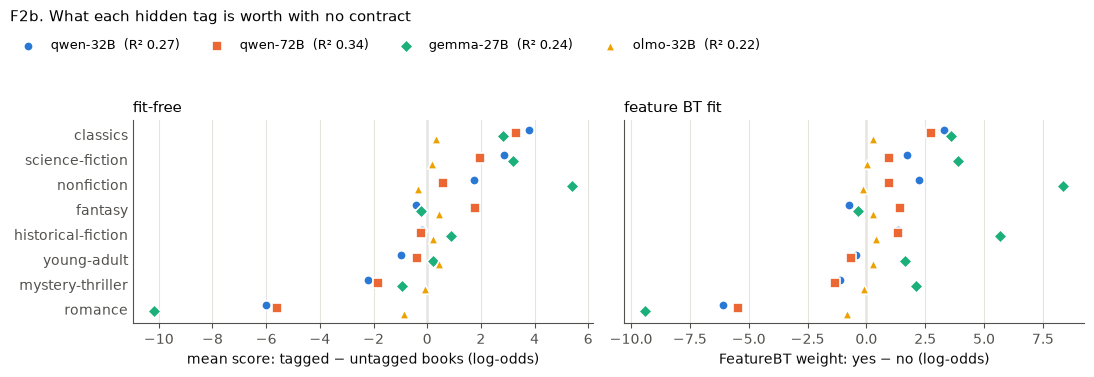

In [11]:
gap = pd.DataFrame({m: {t: base[m][[has(b, t) for b in base.index]].mean() - base[m][[not has(b, t) for b in base.index]].mean()
                        for t in TAGS} for m in MODELS})
W, R2 = {}, {}
cols = ["score_a", "score_b"] + [f"a_{t}" for t in TAGS] + [f"b_{t}" for t in TAGS]
for m in MODELS:
    bt = FeatureBT(pmi_c=0.0, r2_warn=None).fit(runs[(m, "none")][cols])
    W[m] = {t: bt.weights_[t]["yes"] - bt.weights_[t]["no"] for t in TAGS}; R2[m] = bt.r2_
W = pd.DataFrame(W); W.loc["R2"] = pd.Series(R2)
tord = gap.mean(axis=1).sort_values(ascending=False).index

# F2b: what each hidden tag is worth, two ways.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
model_dots(axes[0], gap.loc[tord], "mean score: tagged − untagged books (log-odds)")
model_dots(axes[1], W.loc[tord], "FeatureBT weight: yes − no (log-odds)")
axes[0].set_title("fit-free", loc="left"); axes[1].set_title("feature BT fit", loc="left")
lab = [f"{m}  (R² {R2[m]:.2f})" for m in MODELS]
fig.legend(axes[0].get_legend_handles_labels()[0], lab, loc="upper left", bbox_to_anchor=(0.005, 0.935), frameon=False, ncol=4, fontsize=9)
fig.suptitle("F2b. What each hidden tag is worth with no contract", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/F2b_tag_effects.png", dpi=150); plt.show()

- **Romance is the disliked genre** in qwen and gemma: −5.6 to −10.2 log-odds vs untagged books (OLMo −0.9 on
  its quiet scale). Both views agree.
- **Classics and science fiction are liked** (classics +2.8 … +3.8 fit-free in qwen and gemma). Gemma also likes
  nonfiction (+5.4 fit-free, +8.4 in the fit).
- **The tags explain only a quarter of the default** (R² 0.22–0.34, in the legend): the choice is mostly about the
  book itself, not its genre.

## 4. Contracts: does the model comply, and what does it cost?

**Mixed pairs** = one book has the requested tag, the other does not. We ask: of the mixed pairs, how often does
the tagged book win — with no contract, and with the contract?

In [12]:
rows = []
for m in MODELS:
    for c in CONS[1:]:
        if (m, c) not in D: continue
        t = c.split("=")[0]; out = {"model": m, "contract": t}
        for name, k in [("none", (m, "none")), ("con", (m, c))]:
            d = D[k]; mix = d[d.a_title.map(lambda b: has(b, t)) & ~d.b_title.map(lambda b: has(b, t))]
            out[f"win_{name}"] = (mix.m > 0).mean(); out[f"D_{name}"] = mix.m.mean()
        dl = score[(m, c)] - score[(m, "none")]; tagged = [b for b in dl.index if has(b, t)]
        out["rms_move"] = np.sqrt((dl ** 2).mean())
        out["in_topN"] = f"{int(score[(m, c)].rank(ascending=False)[tagged].le(len(tagged)).sum())}/{len(tagged)}"
        rows.append(out)
CT = pd.DataFrame(rows).set_index(["model", "contract"])
CT["in_top"] = CT.in_topN.map(lambda s: eval(s))

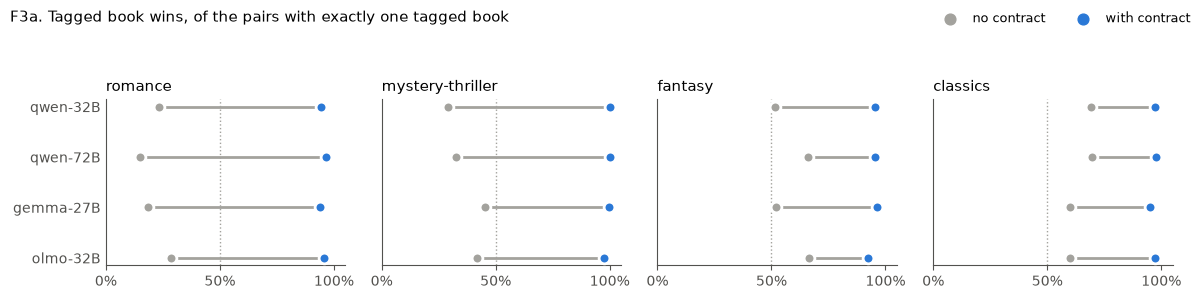

In [13]:
# F2: share of mixed pairs won by the tagged book, without -> with the contract.
fig, axes = plt.subplots(1, 4, figsize=(12, 3.0), sharey=True)
for ax, t in zip(axes, ["romance", "mystery-thriller", "fantasy", "classics"]):
    sub = CT.xs(t, level="contract").reindex(MODELS)
    y = np.arange(len(MODELS))[::-1]
    for yi, m in zip(y, MODELS):
        if m not in sub.dropna().index:
            ax.text(0.5, yi, "not landed yet", ha="center", va="center", fontsize=8, color=INK2); continue
        a, b = sub.loc[m, "win_none"], sub.loc[m, "win_con"]
        ax.plot([a, b], [yi, yi], color=GRAY, lw=2, zorder=1)
        ax.scatter([a], [yi], s=60, color=GRAY, zorder=2, edgecolor="white", linewidth=2)
        ax.scatter([b], [yi], s=60, color=BLUE, zorder=3, edgecolor="white", linewidth=2)
    ax.axvline(0.5, color=GRAY, lw=1, ls=":", zorder=0)
    ax.set_xlim(0, 1.05); ax.set_xticks([0, .5, 1], ["0%", "50%", "100%"]); ax.set_title(t, loc="left")
    ax.set_yticks(y, MODELS); ax.tick_params(axis="y", length=0)
axes[0].scatter([], [], color=GRAY, s=60, label="no contract"); axes[0].scatter([], [], color=BLUE, s=60, label="with contract")
fig.legend(loc="upper right", frameon=False, ncol=2, fontsize=9)
fig.suptitle("F3a. Tagged book wins, of the pairs with exactly one tagged book", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(f"{FIG}/F3a_contract_win_rate.png", dpi=150); plt.show()

- **Every contract is obeyed, even against the default**: 93–100% of mixed pairs, in every model.
- **`romance` is the hardest test**: with no contract the tagged book wins only 15–28% of mixed pairs, and with the
  contract 94–96%.
- **`mystery-thriller` reaches 100%** in qwen-32B, qwen-72B and gemma (OLMo 97%).

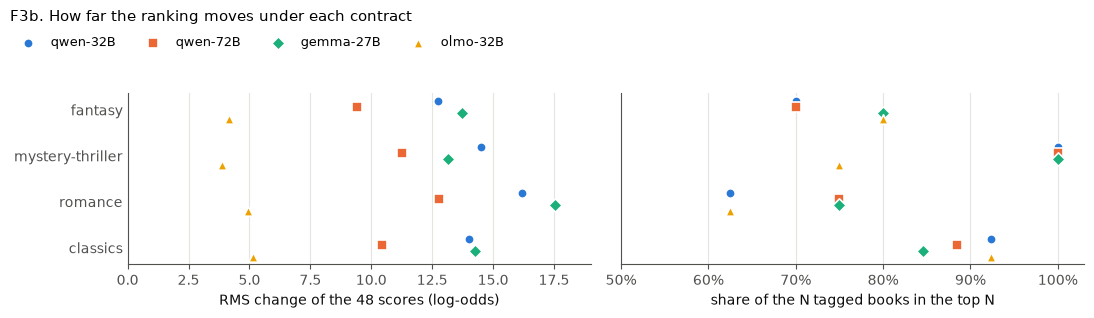

In [14]:
# F3b: how much the whole ranking moves, and how many requested books reach the top.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
CONT = ["fantasy", "mystery-thriller", "romance", "classics"]
model_dots(axes[0], CT.rms_move.unstack(0).loc[CONT, MODELS], "RMS change of the 48 scores (log-odds)", zero=False)
model_dots(axes[1], CT.in_top.unstack(0).loc[CONT, MODELS], "share of the N tagged books in the top N", zero=False)
axes[0].set_xlim(0, 19); axes[1].set_xlim(0.5, 1.03)
axes[1].xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.935), frameon=False, ncol=4, fontsize=9)
fig.suptitle("F3b. How far the ranking moves under each contract", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/F3b_move_and_top.png", dpi=150); plt.show()

- **The control does not stay still.** `classics` agrees with the default taste, yet it moves the scores as much as
  the others: RMS 5.2–14.3 vs 3.9–17.5. Section 5 shows why.
- **`romance` moves the ranking the most** in 3 of 4 models (qwen-32B 16.2, qwen-72B 12.8, gemma 17.5). OLMo moves
  3.9–5.2 everywhere, on its quieter scale.
- **The requested books mostly fill the top**, but not fully: `mystery-thriller` 8/8 (OLMo 6/8), `classics`
  22–24/26, `fantasy` 7–8/10, `romance` only 5–6/8. Some untagged books push in (section 5: Twilight).

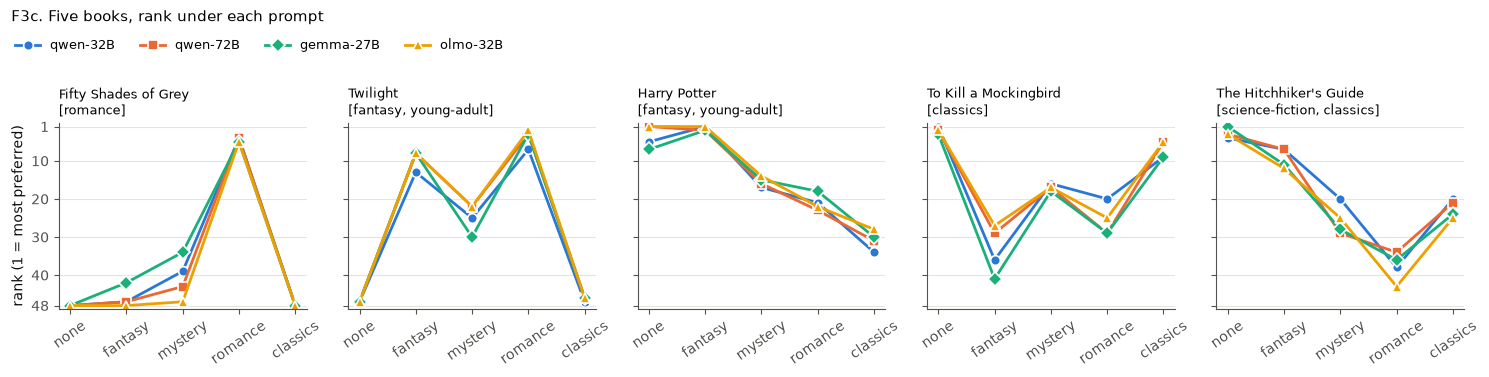

In [15]:
# F3c: the rank of five key books under each prompt (1 = top).
KEY = ["Fifty Shades of Grey", "Twilight", "Harry Potter and the Sorcerer's Stone", "To Kill a Mockingbird", "The Hitchhiker's Guide to the Galaxy"]
NICK = {"Harry Potter and the Sorcerer's Stone": "Harry Potter", "The Hitchhiker's Guide to the Galaxy": "The Hitchhiker's Guide"}
RK = {(m, c): score[(m, c)].rank(ascending=False) for m in MODELS for c in CONS}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.8), sharey=True)
x = np.arange(len(CONS))
for ax, b in zip(axes, KEY):
    for m in MODELS:
        ax.plot(x, [RK[(m, c)][b] for c in CONS], color=MC[m], marker=MK[m], lw=2, ms=7, mec="white", mew=1.2, label=m)
    ax.set_xticks(x, [SHORTC[c] for c in CONS], rotation=35)
    ax.set_title(f"{NICK.get(b, b)}\n[{', '.join(t for t in TAGS if has(b, t))}]", loc="left", fontsize=9.5)
    ax.grid(axis="y", color=GRID, lw=0.8); ax.set_axisbelow(True)
axes[0].set_ylim(49, 0); axes[0].set_yticks([1, 10, 20, 30, 40, 48]); axes[0].set_ylabel("rank (1 = most preferred)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper left", bbox_to_anchor=(0.005, 0.935), frameon=False, ncol=4, fontsize=9)
fig.suptitle("F3c. Five books, rank under each prompt", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.9)); fig.savefig(f"{FIG}/F3c_key_books.png", dpi=150); plt.show()

- **Fifty Shades of Grey: 48th → 4th–5th under `romance`**, in all four models. The strongest dislike is gone with
  one sentence. Under every other contract it stays near the bottom (34th–48th).
- **Twilight (47th, not tagged romance) → 2nd–7th under `romance`**, and 8th–13th under `fantasy`.
- **Harry Potter: 1st–7th → 1st–2nd under `fantasy`, but 28th–34th under `classics`** — it is not a classic.
- **To Kill a Mockingbird is the classic, and still falls under `classics`**: 1st–3rd → 5th–9th. Under `fantasy`
  it falls to 27th–41st.
- **The Hitchhiker's Guide is tagged `classics` and falls under `classics`** too: 1st–4th → 20th–25th.

## 5. Inside the contract: the model's taste, or "the most typical book of the genre"?

The contract says *which* genre; it does not say which fantasy book. If the model completed it with its own
preference, the tagged books would keep their default order. Test against **typicality** = the book's share of
that genre among its Goodreads genre shelves (section 0).

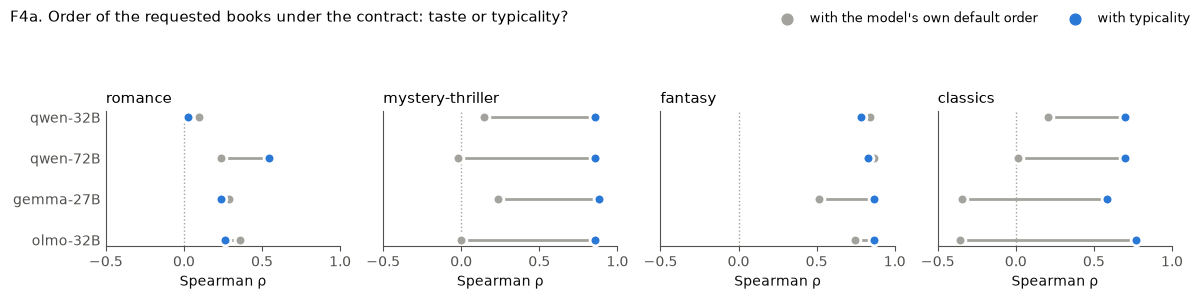

In [16]:
share = mb.genre_shares(mb.load_raw()[1])
gid = meta.goodreads_book_id
rows = []
for m in MODELS:
    for c in CONS[1:]:
        if (m, c) not in score: continue
        t = c.split("=")[0]; b0, b1 = score[(m, "none")], score[(m, c)]
        sh = pd.Series({b: share.loc[gid[b], t] for b in b1.index})
        tg = [b for b in b1.index if has(b, t)]
        rows.append({"model": m, "contract": t,
                     "tagged: rho(score, default)": spearmanr(b1[tg], b0[tg])[0],
                     "tagged: rho(score, typicality)": spearmanr(b1[tg], sh[tg])[0],
                     "all 48: rho(move, typicality)": spearmanr(b1 - b0, sh)[0]})
TY = pd.DataFrame(rows).set_index(["model", "contract"])

# F4a: among the requested books, does the new order follow the model's own taste, or typicality?
fig, axes = plt.subplots(1, 4, figsize=(12, 3.0), sharey=True)
for ax, t in zip(axes, ["romance", "mystery-thriller", "fantasy", "classics"]):
    sub = TY.xs(t, level="contract").reindex(MODELS)
    y = np.arange(len(MODELS))[::-1]
    for yi, m in zip(y, MODELS):
        a, b = sub.loc[m, "tagged: rho(score, default)"], sub.loc[m, "tagged: rho(score, typicality)"]
        ax.plot([a, b], [yi, yi], color=GRAY, lw=2, zorder=1)
        ax.scatter([a], [yi], s=60, color=GRAY, zorder=2, edgecolor="white", linewidth=2)
        ax.scatter([b], [yi], s=60, color=BLUE, zorder=3, edgecolor="white", linewidth=2)
    ax.axvline(0, color=GRAY, lw=1, ls=":", zorder=0)
    ax.set_xlim(-0.5, 1.0); ax.set_title(t, loc="left"); ax.set_yticks(y, MODELS); ax.tick_params(axis="y", length=0)
    ax.set_xlabel("Spearman ρ")
axes[0].scatter([], [], color=GRAY, s=60, label="with the model's own default order"); axes[0].scatter([], [], color=BLUE, s=60, label="with typicality")
fig.legend(loc="upper right", frameon=False, ncol=2, fontsize=9)
fig.suptitle("F4a. Order of the requested books under the contract: taste or typicality?", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.86)); fig.savefig(f"{FIG}/F4a_taste_vs_typicality.png", dpi=150); plt.show()

- **Inside the requested genre, the order follows typicality, not the model's taste** (blue far right of gray).
  With typicality ρ 0.58–0.88; with the model's own default −0.36 to +0.36. Two exceptions:
- **`fantasy`**: here the most typical book is also a favourite (Harry Potter), so taste and typicality agree
  (0.52–0.87 both).
- **`romance`**: typicality is weak too (ρ 0.02–0.55). What rises are the canonical romances (Jane Eyre, Pride and
  Prejudice) and Twilight, not the books with the most romance shelves (F4b).

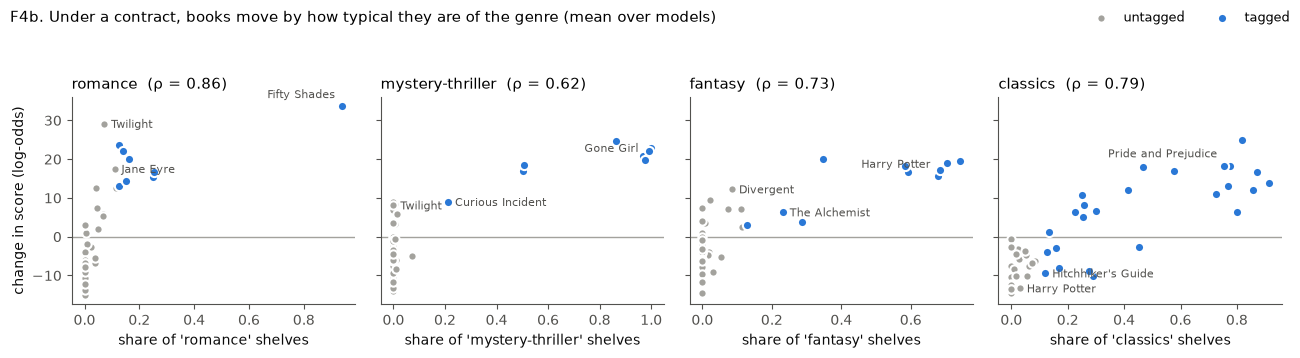

In [17]:
# F3: per contract, how much each book moved (mean over models) against how typical it is of the genre.
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
LABEL = {"romance": ["Twilight", "Fifty Shades of Grey", "Jane Eyre"],
         "mystery-thriller": ["The Curious Incident of the Dog in the Night-Time", "Gone Girl", "Twilight"],
         "fantasy": ["Divergent", "The Alchemist", "Harry Potter and the Sorcerer's Stone"],
         "classics": ["The Hitchhiker's Guide to the Galaxy", "Pride and Prejudice", "Harry Potter and the Sorcerer's Stone"]}
SHORT = {"The Curious Incident of the Dog in the Night-Time": "Curious Incident", "Harry Potter and the Sorcerer's Stone": "Harry Potter",
         "The Hitchhiker's Guide to the Galaxy": "Hitchhiker's Guide", "Fifty Shades of Grey": "Fifty Shades"}
for ax, t in zip(axes, ["romance", "mystery-thriller", "fantasy", "classics"]):
    c = f"{t}=yes"; ms = [m for m in MODELS if (m, c) in score]
    dl = pd.concat([score[(m, c)] - score[(m, "none")] for m in ms], axis=1).mean(axis=1)
    sh = pd.Series({b: share.loc[gid[b], t] for b in dl.index})
    tg = np.array([has(b, t) for b in dl.index])
    ax.axhline(0, color=GRAY, lw=1, zorder=0)
    ax.scatter(sh[~tg], dl[~tg], s=36, color=GRAY, edgecolor="white", linewidth=1.5, label="untagged", zorder=2)
    ax.scatter(sh[tg], dl[tg], s=44, color=BLUE, edgecolor="white", linewidth=1.5, label=f"tagged", zorder=3)
    for b in LABEL[t]:
        ax.annotate(SHORT.get(b, b), (sh[b], dl[b]), xytext=(5, -3) if sh[b] < 0.5 else (-5, 6), ha="left" if sh[b] < 0.5 else "right", textcoords="offset points", fontsize=8, color=INK2)
    ax.set_title(f"{t}  (ρ = {spearmanr(dl, sh)[0]:.2f})", loc="left"); ax.set_xlabel(f"share of '{t}' shelves")
axes[0].set_ylabel("change in score (log-odds)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", frameon=False, ncol=2, fontsize=9)
fig.suptitle("F4b. Under a contract, books move by how typical they are of the genre (mean over models)", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.92)); fig.savefig(f"{FIG}/F4b_typicality.png", dpi=150); plt.show()

- **Across all 48 books, how far a book moves follows how typical it is of the genre**: ρ 0.57–0.90 per model
  (0.62–0.86 on the model mean, in the panel titles).
- **`classics` reshuffles because of this.** "Classics" means *the canonical classics*, not "the good books I
  already liked": Pride and Prejudice rises; Harry Potter (not a classic) and The Hitchhiker's Guide (a weak
  classic) fall.
- **The model has its own idea of the genre.** Twilight is not tagged romance (7% of shelves) but rises more than any
  tagged romance except Fifty Shades under `romance` (+29.1 vs +33.6 on average); the untagged Jane Eyre (+17.5) and Little Women (+12.6) follow. Under `fantasy` the
  untagged dystopias rise (Divergent +12.3, The Giver +7.0) about as much as the tagged Alchemist (+6.3), while the
  typical fantasy books rise ~15–20.

## 6. Findings

1. **One shared taste.** The 4 models agree (ρ 0.59–0.83) and share the same bottom three (Romeo and Juliet,
   Twilight, Fifty Shades). The taste follows the readers' rating (ρ 0.42–0.52), not fame. Romance is disliked.
2. **The tags explain little of it** (R² 0.22–0.34): the choice is about the book.
3. **Contracts are obeyed, even against the default**: 93–100% of mixed pairs. Under `romance`, Fifty Shades
   goes 48th → 4th–5th in all four models.
4. **The contract does not get completed with the model's taste.** Inside the requested genre the order follows
   how typical a book is of the genre (ρ 0.58–0.88), not the model's default (ρ ≈ 0). So "the agreeing contract"
   `classics` is not a control: it moves the scores as much as the others, and Harry Potter falls from the top to ~30th.
5. **The model's genre ≠ the readers' tags**: Twilight behaves as romance, Divergent as fantasy, The Alchemist does not.

All 20 runs are in (olmo-32B `romance`, job 1447796, landed 2026-10-13 and changes no conclusion).

**Open:** a contract that
names the genre *and* asks for quality ("I prefer good fantasy") would show whether the taste comes back.